<a href="https://colab.research.google.com/github/abhimanyu-05-2006/YuvaIntern-ML-Engineer-Tasks/blob/main/Task_4_Tool_Mastery_Pipeline.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
from scipy import stats
import time

# 1. High-Performance Matrix Operations & Vectorization Benchmark
np.random.seed(101)
matrix_size = (1000, 1000)
A = np.random.randn(*matrix_size)
B = np.random.randn(*matrix_size)

# Benchmark Matrix Multiplication Time
t_start = time.perf_counter()
C = np.matmul(A, B)
t_execution = (time.perf_counter() - t_start) * 1000

# 2. Statistical Analysis using SciPy
sample_data = np.random.normal(loc=50, scale=10, size=500)
skewness = stats.skew(sample_data)
kurtosis = stats.kurtosis(sample_data)
t_stat, p_val = stats.ttest_1samp(sample_data, popmean=50)

print(f"[NUMPY BENCHMARK] 1000x1000 Matrix Multiplication: {t_execution:.2f} ms")
print(f"[SCIPY STATS] Sample Skewness: {skewness:.4f} | Kurtosis: {kurtosis:.4f}")
print(f"[HYPOTHESIS TEST] One-sample t-test t-statistic: {t_stat:.4f}, p-value: {p_val:.4f}")

[NUMPY BENCHMARK] 1000x1000 Matrix Multiplication: 70.83 ms
[SCIPY STATS] Sample Skewness: -0.0640 | Kurtosis: -0.1078
[HYPOTHESIS TEST] One-sample t-test t-statistic: 0.3814, p-value: 0.7031


In [2]:
import pandas as pd

# Load synthetic multi-channel retail dataset
np.random.seed(42)
n_rows = 500

df_retail = pd.DataFrame({
    'transaction_id': [f"TXN_{i:05d}" for i in range(1, n_rows + 1)],
    'store_category': np.random.choice(['Electronics', 'Apparel', 'Grocery', 'Home'], size=n_rows),
    'unit_price': np.round(np.random.uniform(10.0, 500.0, size=n_rows), 2),
    'quantity': np.random.randint(1, 10, size=n_rows),
    'discount_pct': np.random.choice([0.0, 0.05, 0.10, 0.15, 0.20], size=n_rows),
    'customer_rating': np.random.choice([1, 2, 3, 4, 5], size=n_rows, p=[0.05, 0.1, 0.2, 0.4, 0.25])
})

# Method Chaining Pipeline for Feature Engineering & Pivot Aggregation
processed_df = (
    df_retail
    .assign(gross_revenue=lambda x: x['unit_price'] * x['quantity'])
    .assign(net_revenue=lambda x: x['gross_revenue'] * (1 - x['discount_pct']))
    .query('net_revenue > 20.0')
)

pivot_summary = processed_df.pivot_table(
    index='store_category',
    values=['gross_revenue', 'net_revenue', 'customer_rating'],
    aggfunc={'gross_revenue': 'sum', 'net_revenue': 'sum', 'customer_rating': 'mean'}
).round(2)

print("--- Pandas Production Pipeline Output ---")
print(f"Total Transactions Processed: {len(processed_df)} / {n_rows}")
print("\n--- Pivot Table Summary by Category ---")
print(pivot_summary)

--- Pandas Production Pipeline Output ---
Total Transactions Processed: 499 / 500

--- Pivot Table Summary by Category ---
                customer_rating  gross_revenue  net_revenue
store_category                                             
Apparel                    3.81      138981.09    124644.06
Electronics                3.52      153048.71    138968.04
Grocery                    3.75      158171.16    143466.31
Home                       3.70      185974.25    167120.43


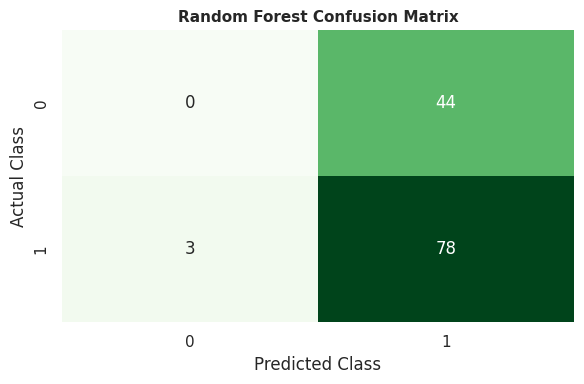

--- Scikit-Learn Classification Report ---
                    precision    recall  f1-score   support

Low/Mid Rating (0)       0.00      0.00      0.00        44
   High Rating (1)       0.64      0.96      0.77        81

          accuracy                           0.62       125
         macro avg       0.32      0.48      0.38       125
      weighted avg       0.41      0.62      0.50       125



In [3]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report, confusion_matrix

# Feature Matrix & Target Setup
X = processed_df[['unit_price', 'quantity', 'discount_pct', 'net_revenue']]
# High Rating Class (4 or 5 = High Satisfaction [1], else [0])
y = (processed_df['customer_rating'] >= 4).astype(int)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.25, random_state=42, stratify=y)

# Feature Scaling & Model Execution
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

clf = RandomForestClassifier(n_estimators=100, max_depth=5, random_state=42)
clf.fit(X_train_scaled, y_train)

y_pred = clf.predict(X_test_scaled)

# Model Performance Diagnostics & Confusion Matrix Plot
sns.set_theme(style="white")
fig, ax = plt.subplots(figsize=(6, 4))
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Greens', cbar=False, ax=ax)
ax.set_title("Random Forest Confusion Matrix", fontsize=11, fontweight='bold')
ax.set_xlabel("Predicted Class")
ax.set_ylabel("Actual Class")
plt.tight_layout()
plt.show()

print("--- Scikit-Learn Classification Report ---")
print(classification_report(y_test, y_pred, target_names=['Low/Mid Rating (0)', 'High Rating (1)']))